# CsI(Tl)–SiPM：run 12 噪声状态能否解释 PID 带宽差异？

2026-10-29，接续英文提交 `c13601b`（已推送）、[下一步检查笔记](codex_0001_csi_next_steps_review.ipynb)与[光电子统计笔记](codex_0001_csi_pid_photon_statistics.ipynb)。

本轮完成 **18 组原生 C++ 响应重放**，只改变电子噪声强度、基线/方差状态及相关谱。源仍为原 Geant4 ²⁴¹Am 完整衰变历史，光子输运、雪崩、无噪声信号、发光/读出参数和信号期残差保持固定。**没有复制实验波形或直接给 PID 分数加宽。**

结果：后段基线 RMS 漂移能够得到近似描述，QDC 与 PCA 的宽度点估计向实测靠近；但三个新对照、三种方法的后段配对变化95%区间均包含0，**统计上还不能确认带宽改善**。平均时间宽度比的点估计仍约0.82，尚未完成全部PID分布的一致性验证。下面同时列出所有预先冻结的对照与统计区间。


In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/run12_noise_state_20261029'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def numbers(values,precision=3):return ' / '.join(f'{x:.{precision}f}' for x in values)
def ci_text(row,method,block='64',field='IQR_ratio_CI95'):
    lo,hi=row['uncertainty_by_data_block'][block][field][method]['estimate95']
    return f'[{lo:.3f}, {hi:.3f}]'
r=read(OUT/'assessment.json');p=read(OUT/'protocol.json')
variants=p['noise_variants'];segments=['first60','middle20','last20']
names={'baseline':'原噪声','scale':'只改RMS','states':'基线/方差状态','spectrum_states':'状态+相关谱'}
print('Python / NumPy:',sys.version.split()[0],np.__version__)
print('唯一母事件：',r['unique_parent_mothers'],'；新增独立母事件：',r['new_native_mothers'])
print('原共同Q内MC：',r['old_common_MC'],'；实际原生重放数：',len(p['entries'])-1)
assert r['prior_baseline_reproduced'] and r['no_PID_based_candidate_refit']

Python / NumPy: 3.13.5 2.5.4
唯一母事件： 24000 ；新增独立母事件： 0
原共同Q内MC： 206 ；实际原生重放数： 18


## 1. 预先冻结的比较与交叉估计

原始 run 12 有7516条记录。沿用已冻结的波形队列和前60%/中20%/后20%分段。
各段按原始事件号 `floor(id/64) % 2` 分两组：只用一组的前触发样点估计状态，在另一组检查，然后交换。
状态估计用前128点；相关谱用前256点（512 ns，线性去趋势）。这一步**不用主脉冲、PID分数或主带门切**。
基线均值/对数方差混合模型在一/两状态间由校准组 BIC 选择，且每个成分至少20条有效观测。

四组响应为：原模型；保留原谱/原状态分布只改 RMS；保留原谱重估基线/方差状态；重估状态和相关谱。
所有配置在重放前写入 `protocol.json` 并保存 SHA-256。没有根据留出 PID 结果再调参或隐藏不理想的候选。

每个模拟母事件用固定随机数分配一个评估组，与该段实验组比例相匹配；每段每个母事件只保留一份响应。
18组重放共用24000个原母事件，不计成432000个独立样本。共同Q区间与支持箱0/1/2保持原样。

**解释边界：**只有这次新增噪声估计进行了交叉估计。旧的脉冲/信号参数已经用过前60%；后段前触发样点也参与相应条件估计。
因此这是以采集状态为条件的内部验证，不是从前段预测后段的盲检。相邻块仍可能相关；本轮增加块长128的区间敏感性，但不把ID不重合称为完全独立。


In [2]:
rows=[]
for seg in segments:
    for fold in [0,1]:
        f=read(PROJECT/p['groups'][seg]['folds'][str(fold)]['fit'])
        a=f['state_fit_original_spectrum']['chosen'];b=f['state_fit_new_spectrum']['chosen']
        rows.append([seg,fold,f['calibration_n'],f['evaluation_n'],f"{f['RMS_scale']:.3f}",len(a['states']),len(b['states'])])
display(Markdown(table(['段','评估组','校准数','留出数','RMS尺度','原谱状态数','新谱状态数'],rows)))
print('共同Q区间:',p['q_edges'][0],p['q_edges'][-1],'；等权支持箱:',p['support_bins'])

共同Q区间: 201824.1125 418733.2 ；等权支持箱: [0, 1, 2]


|段|评估组|校准数|留出数|RMS尺度|原谱状态数|新谱状态数|
|---|---|---|---|---|---|---|
|first60|0|760|787|0.997|2|2|
|first60|1|787|760|1.004|2|2|
|middle20|0|224|236|1.488|2|2|
|middle20|1|236|224|1.494|2|2|
|last20|0|196|211|1.743|1|1|
|last20|1|211|196|1.784|1|1|

## 2. 前触发噪声：先检查噪声本身

下表和图对实验使用整段冻结波形队列，不加 PID 主带门切；模拟使用原来的206个共同Q母事件，每个只分配一个状态响应。
图中竖线是事件分布的10%–90%分位，**不是中位数的置信区间**。分组留出结果另存 `assessment.json → noise → folds`。
图中的原谱对照即使调大RMS，仍未重现后段低频增强和相关结构；重估频谱的对照更接近这些特征，这是描述性比较。
RMS 可接近并不等于完整噪声过程已重现：有限512 ns窗口、去趋势、短 FIR 和高斯混合假设，不能唯一识别微秒尺度相关、瞬态或基线与主脉冲的耦合。


|段|实验RMS中位数|原噪声|只改RMS|基线/方差状态|状态+相关谱|
|---|---|---|---|---|---|
|first60|3.167|3.174|3.181|3.174|3.168|
|middle20|4.415|3.174|4.715|4.586|4.657|
|last20|5.677|3.174|5.588|5.531|5.516|

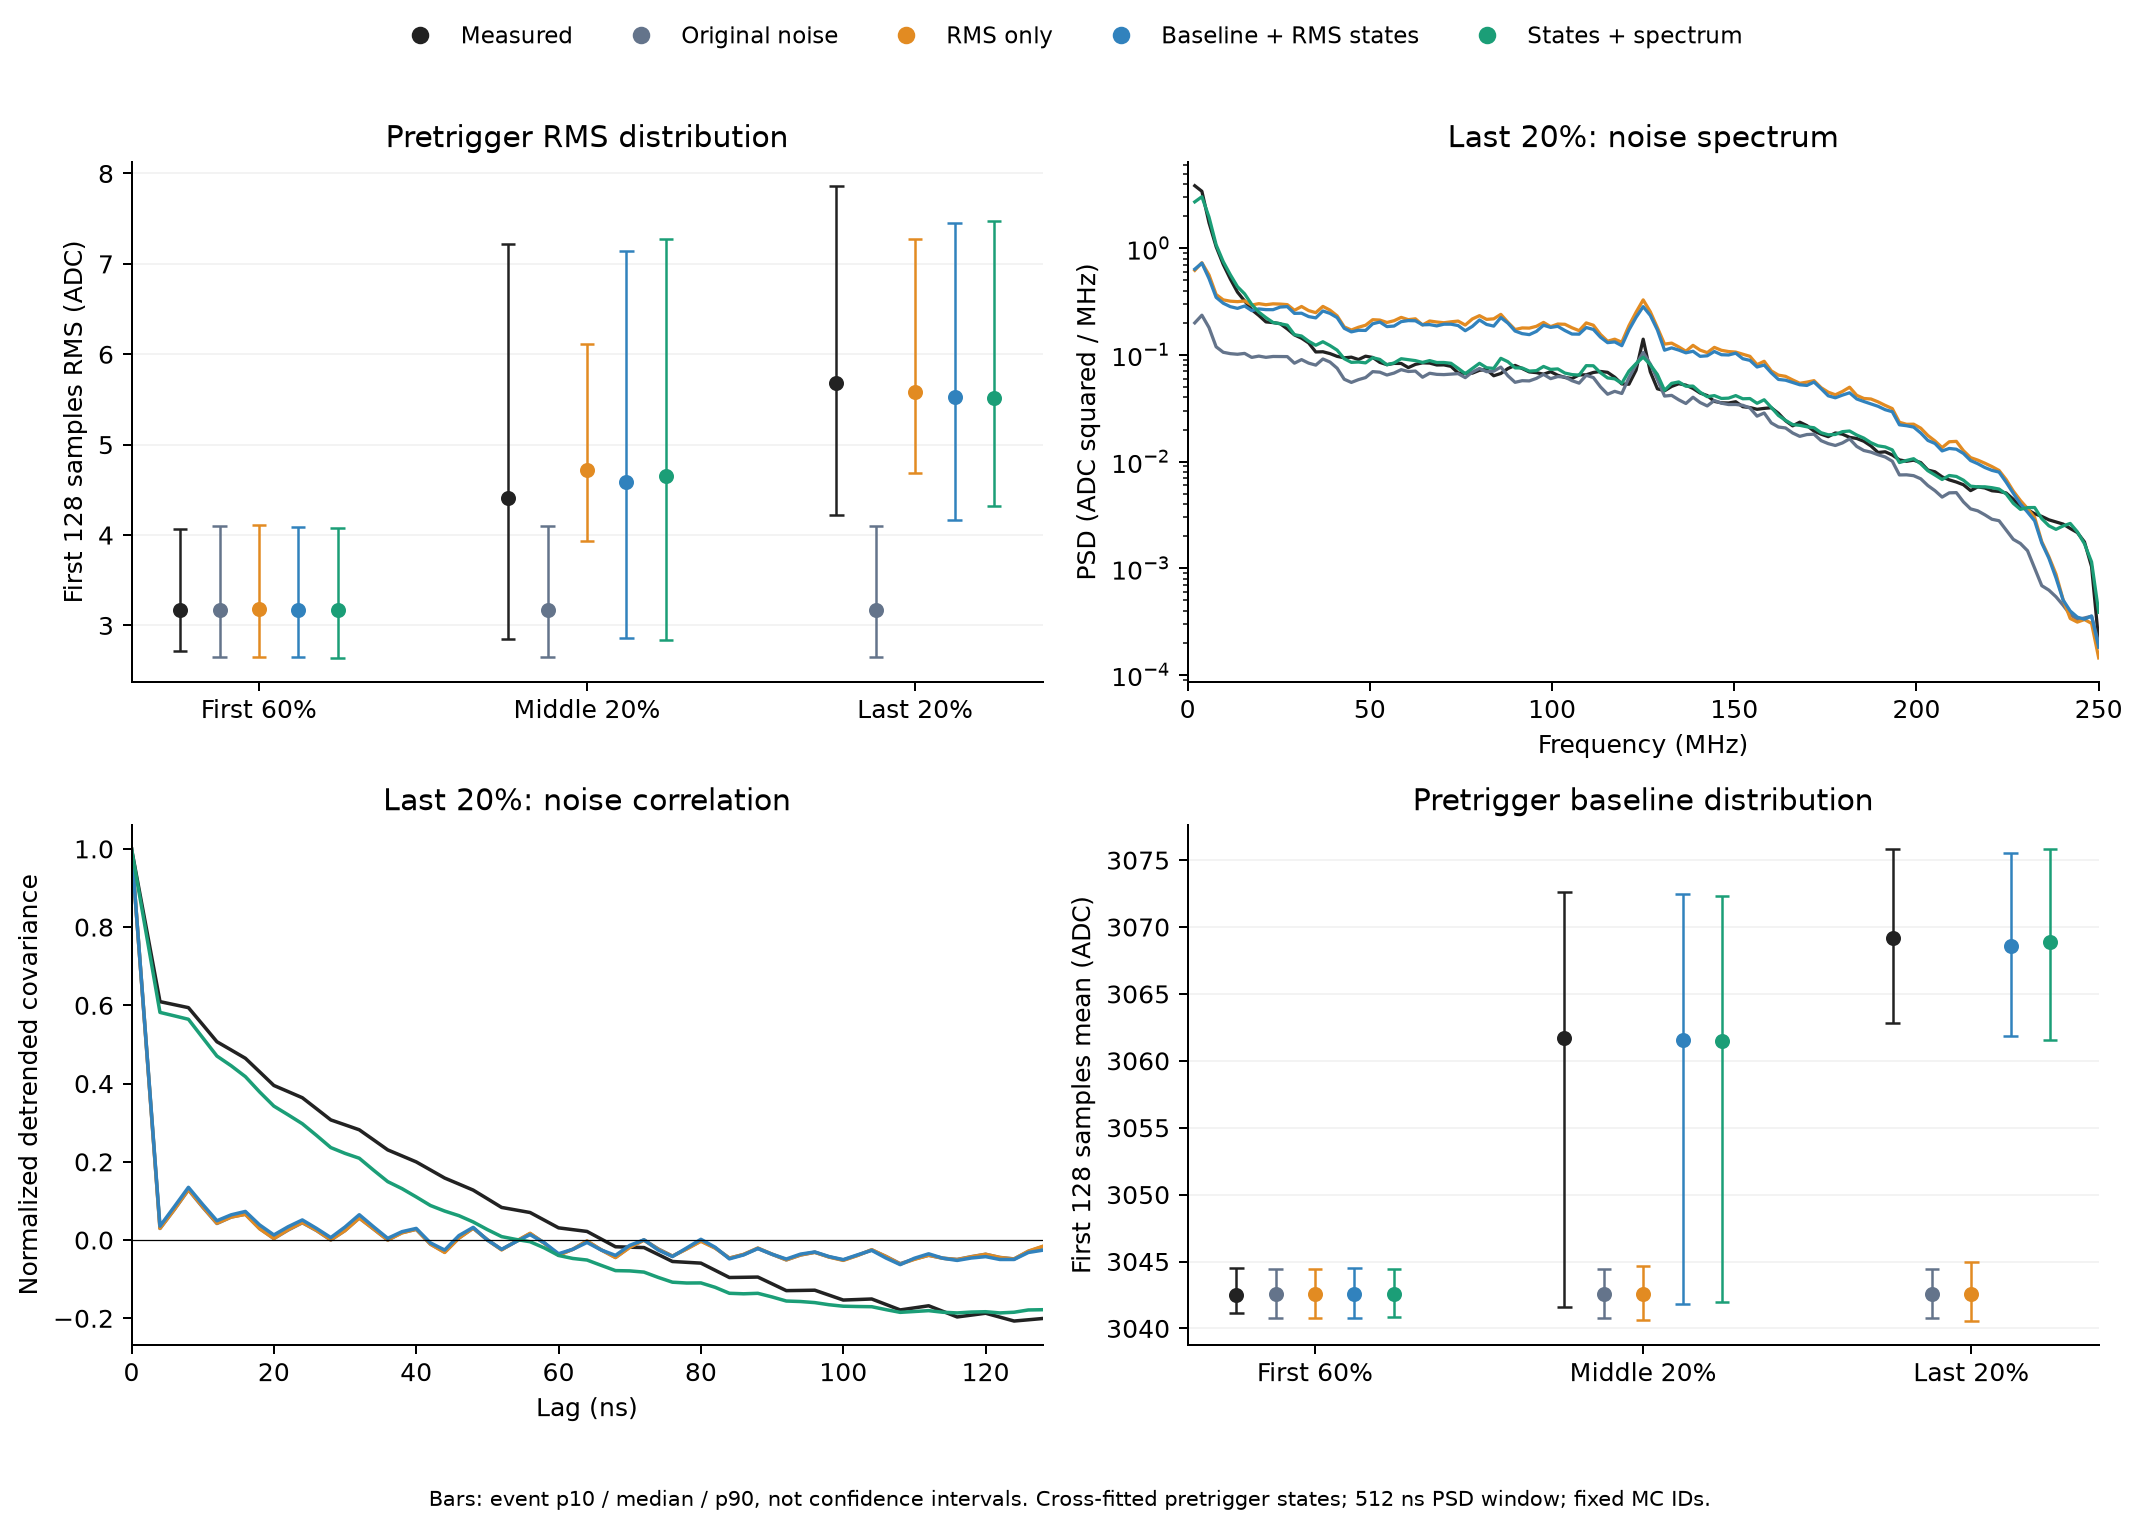

In [3]:
rows=[]
for seg in segments:
    n=r['noise'][seg]
    rows.append([seg,f"{n['data']['RMS_p10_p50_p90'][1]:.3f}",*[f"{n[v]['pooled']['RMS_p10_p50_p90'][1]:.3f}" for v in variants]])
display(Markdown(table(['段','实验RMS中位数']+[names[v] for v in variants],rows)))
display(Image(filename=str(OUT/'figures/noise_state_closure.png')))

## 3. 三种 PID 带宽及成对区间

每个Q箱独立求 IQR，再对原支持箱等权取平方均值的平方根；表中的值是该宽度的 MC/实验比。
实验只在评估时沿用 `Qshort/Qlong < 0.4` 主带诊断，不代表已知纯α样本。²⁴¹Am 同时有γ与衰变电子，源名不作事件真标签。

512次重采样中，同一个母事件计数向量同时用于所有模拟候选和分段；实验按原始序号块重采样。
这样新旧差值保留配对，重放副本不增加有效样本数。区间固定噪声拟合、频谱、母事件分组和旧模型参数，**未包含完整拟合/模型不确定性**，也未作多重比较调整。
原模型点估计逐值复现上一版；本轮为所有候选建立统一的配对重采样，使用新固定种子，512次区间端点会有Monte Carlo变化，未改写旧记录。
本轮后段绝对宽度比区间包含1、配对变化区间包含0，既不能确认改善，也不能据此证明模型等效。


|段|对照|MC数|QDC / 平均时间 / PCA带宽比|平均时间95%区间|
|---|---|---|---|---|
|first60|原噪声|206|0.956 / 0.964 / 0.942|[0.802, 1.142]|
|first60|只改RMS|206|0.956 / 0.964 / 0.943|[0.802, 1.142]|
|first60|基线/方差状态|206|0.943 / 0.965 / 0.943|[0.802, 1.143]|
|first60|状态+相关谱|206|0.949 / 0.965 / 0.944|[0.804, 1.144]|
|middle20|原噪声|206|1.000 / 0.809 / 0.973|[0.639, 0.990]|
|middle20|只改RMS|205|1.055 / 0.818 / 1.005|[0.642, 1.014]|
|middle20|基线/方差状态|206|1.064 / 0.820 / 1.028|[0.635, 1.015]|
|middle20|状态+相关谱|206|1.069 / 0.815 / 1.040|[0.642, 1.009]|
|last20|原噪声|206|0.897 / 0.822 / 0.858|[0.659, 1.025]|
|last20|只改RMS|206|0.949 / 0.846 / 0.902|[0.674, 1.035]|
|last20|基线/方差状态|207|0.953 / 0.829 / 0.922|[0.682, 1.037]|
|last20|状态+相关谱|207|0.928 / 0.817 / 0.945|[0.684, 1.057]|

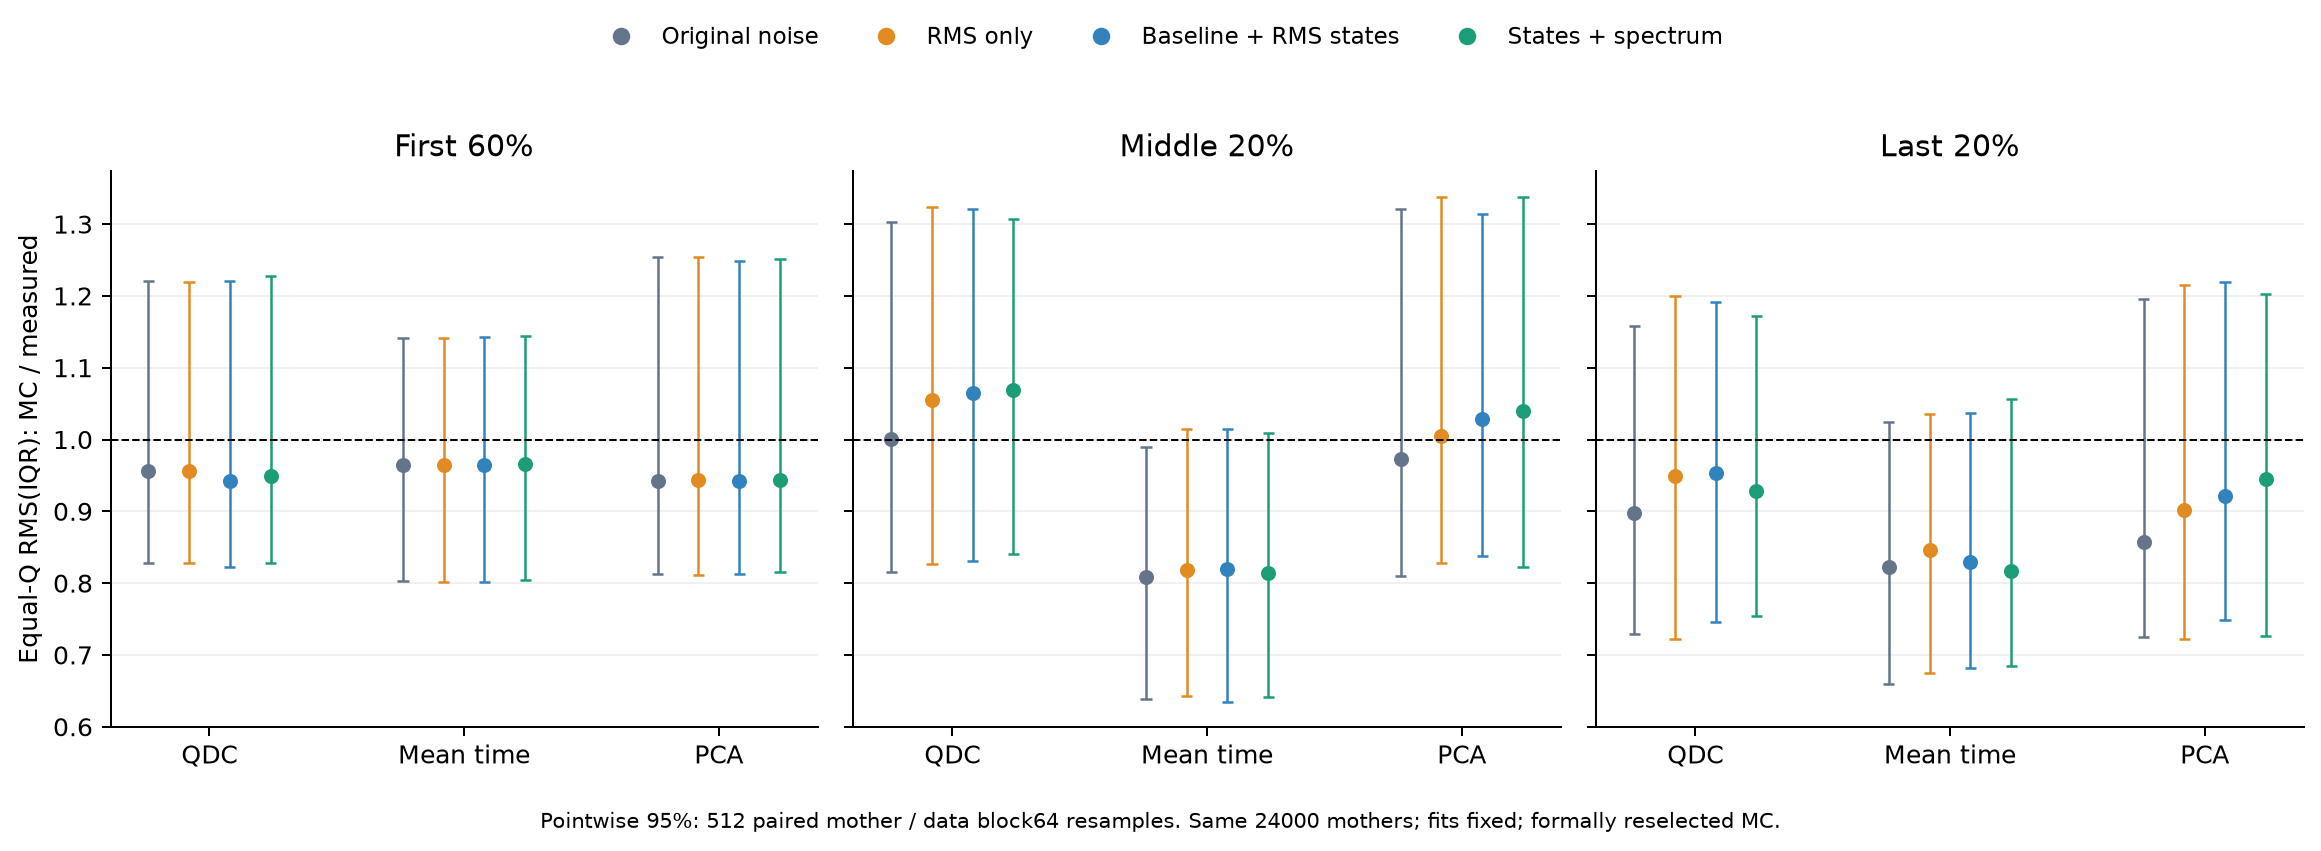

|后段对照|平均时间比|块64区间|块128区间|相对原模型变化|配对变化95%区间|
|---|---|---|---|---|---|
|原噪声|0.822|[0.659, 1.025]|[0.668, 0.978]|+0.000|[0.000, 0.000]|
|只改RMS|0.846|[0.674, 1.035]|[0.674, 0.995]|+0.024|[-0.061, 0.103]|
|基线/方差状态|0.829|[0.682, 1.037]|[0.675, 0.996]|+0.007|[-0.057, 0.093]|
|状态+相关谱|0.817|[0.684, 1.057]|[0.671, 1.006]|-0.005|[-0.094, 0.145]|

In [4]:
rows=[]
for seg in segments:
    for v in variants:
        a=r['checks'][seg]['variants'][v]['reselected']
        rows.append([seg,names[v],a['n_MC'],numbers(a['IQR_ratio']),ci_text(a,1)])
display(Markdown(table(['段','对照','MC数','QDC / 平均时间 / PCA带宽比','平均时间95%区间'],rows)))
display(Image(filename=str(OUT/'figures/noise_pid_widths.png')))
rows=[]
for v in variants:
    a=r['checks']['last20']['variants'][v]['reselected']
    rows.append([names[v],f"{a['IQR_ratio'][1]:.3f}",ci_text(a,1,'64'),ci_text(a,1,'128'),f"{a['paired_delta_ratio'][1]:+.3f}",ci_text(a,1,field='paired_delta_ratio_CI95')])
display(Markdown(table(['后段对照','平均时间比','块64区间','块128区间','相对原模型变化','配对变化95%区间'],rows)))

## 4. 固定事件与固定锚点：检查筛选迁移

主结果重新执行原正式质量与Q筛选。同时保留原206个母事件及原Q分箱，检查相同事件的宽度；再把积分锚点固定到原 ADC 的锚点。
后一个检查依然使用候选波形自己的前128点基线，不是重用原基线值。固定锚点只用于诊断，未改正式算法。
下面画的是相对原噪声的宽度比变化及成对95%区间，0表示没有变化。完整三段和三种定义都在CSV/JSON中。


|段|对照|重筛数|新增数|流失数|固定母事件两组数|
|---|---|---|---|---|---|
|first60|原噪声|206|0|0|101/105|
|first60|只改RMS|206|0|0|101/105|
|first60|基线/方差状态|206|0|0|101/105|
|first60|状态+相关谱|206|0|0|101/105|
|middle20|原噪声|206|0|0|101/105|
|middle20|只改RMS|205|0|1|101/105|
|middle20|基线/方差状态|206|0|0|101/105|
|middle20|状态+相关谱|206|1|1|101/105|
|last20|原噪声|206|0|0|101/105|
|last20|只改RMS|206|1|1|101/105|
|last20|基线/方差状态|207|1|0|101/105|
|last20|状态+相关谱|207|2|1|101/105|

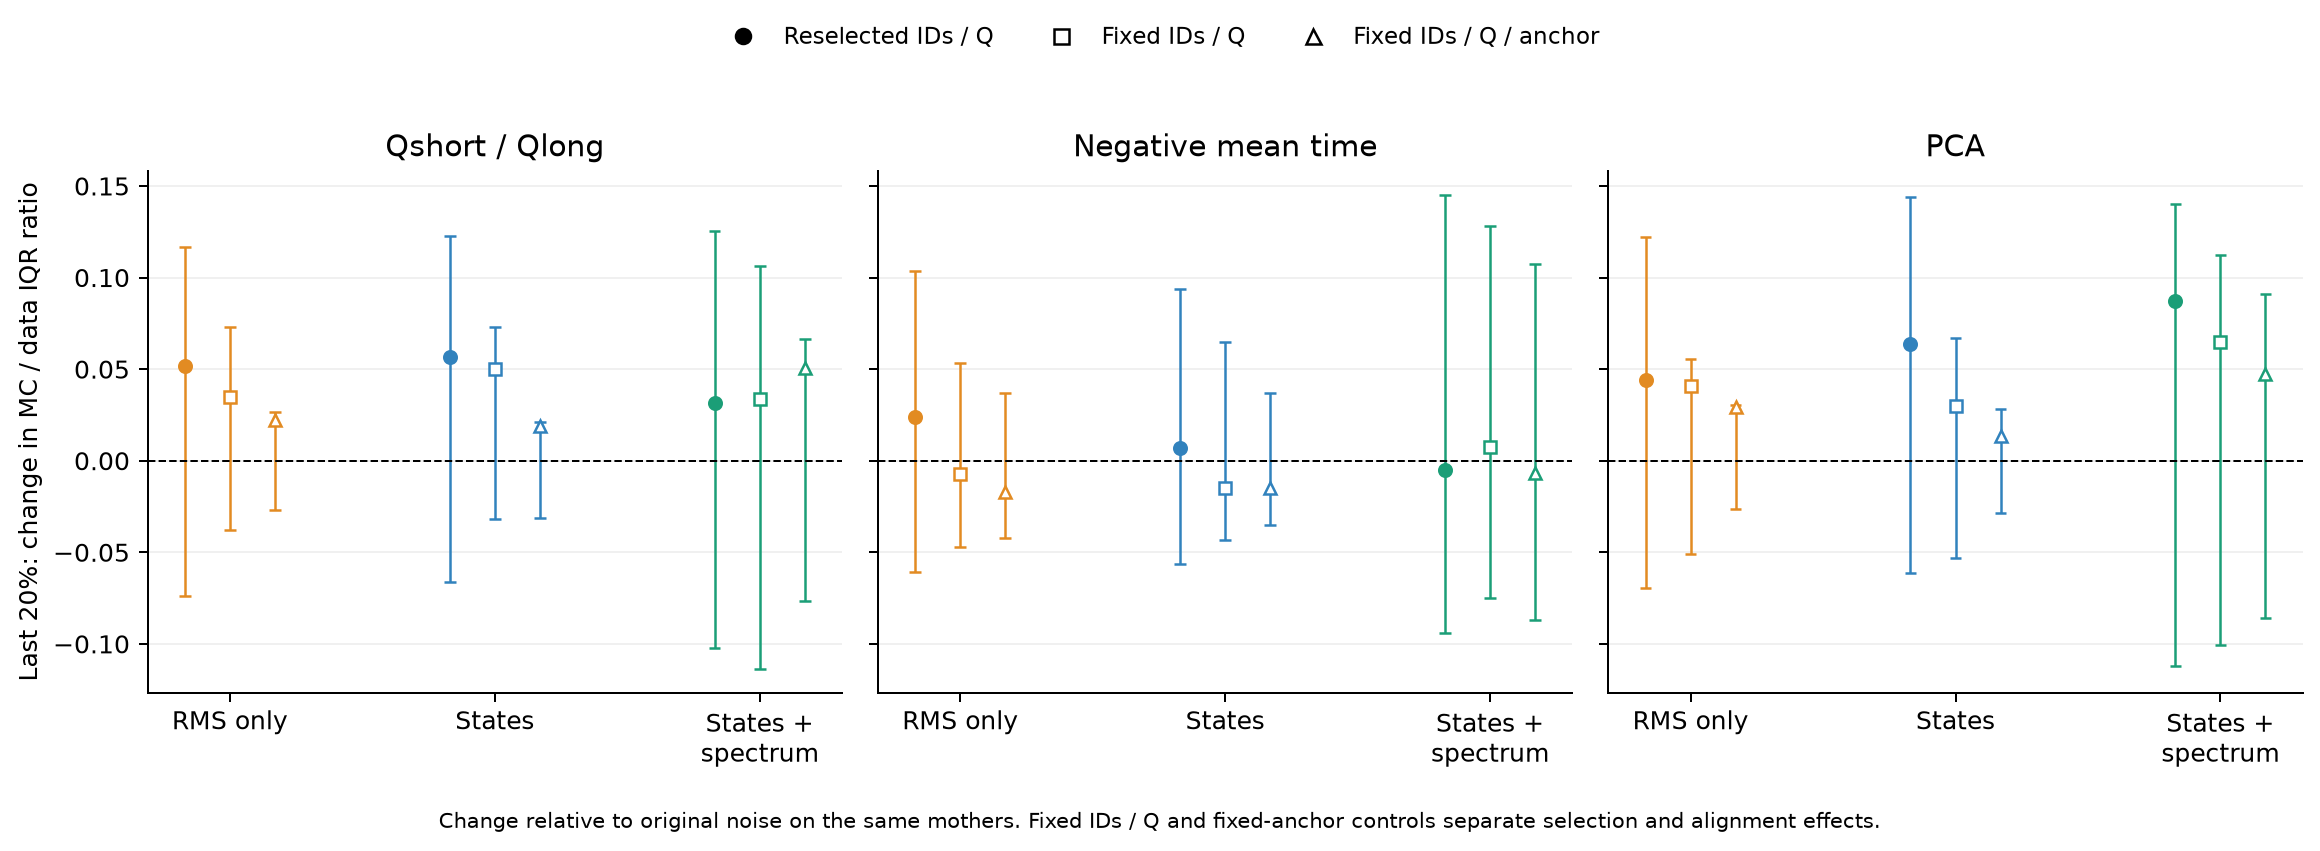

In [5]:
rows=[]
for seg in segments:
    for v in variants:
        a=r['pairing'][f'{seg}__{v}']
        rows.append([seg,names[v],a['selected_n'],len(a['gained']),len(a['lost']),'/'.join(map(str,a['assigned_fixed_mothers_per_fold']))])
display(Markdown(table(['段','对照','重筛数','新增数','流失数','固定母事件两组数'],rows)))
display(Image(filename=str(OUT/'figures/noise_pid_paired_controls.png')))

## 5. 波形均值、带中心和短尺度起伏是否保持

平均 ADC 先扣本事件前128点基线并按 t₁₀ 对齐，然后在原Q支持箱内等权平均；没有按实验幅度缩放模拟波形。
NRMSE为−40至3000 ns的均方根差除以实测均波形峰值。短尺度 F 沿用此前50/102/202 ns定义。
这些是点估计，与上节带宽统计区间用途不同。


|段|对照|均波形NRMSE/峰|均波形峰比|三个F比|三个中心差/实验IQR|
|---|---|---|---|---|---|
|first60|原噪声|1.129%|1.0250|1.030 / 1.017 / 1.026|0.060 / 0.151 / 0.072|
|first60|只改RMS|1.129%|1.0249|1.030 / 1.017 / 1.026|0.060 / 0.150 / 0.072|
|first60|基线/方差状态|1.129%|1.0249|1.030 / 1.018 / 1.027|0.060 / 0.152 / 0.072|
|first60|状态+相关谱|1.129%|1.0250|1.031 / 1.018 / 1.027|0.060 / 0.152 / 0.072|
|middle20|原噪声|1.120%|1.0173|1.052 / 1.037 / 1.038|-0.059 / 0.104 / 0.046|
|middle20|只改RMS|1.201%|1.0208|1.055 / 1.038 / 1.040|-0.047 / 0.115 / 0.073|
|middle20|基线/方差状态|1.113%|1.0166|1.050 / 1.036 / 1.042|-0.051 / 0.101 / 0.070|
|middle20|状态+相关谱|1.167%|1.0191|1.052 / 1.039 / 1.050|-0.054 / 0.100 / 0.028|
|last20|原噪声|1.169%|1.0134|1.065 / 1.037 / 1.042|-0.075 / 0.062 / -0.003|
|last20|只改RMS|1.169%|1.0135|1.073 / 1.040 / 1.043|-0.074 / 0.077 / 0.012|
|last20|基线/方差状态|1.183%|1.0143|1.065 / 1.038 / 1.042|-0.064 / 0.074 / -0.004|
|last20|状态+相关谱|1.217%|1.0170|1.063 / 1.036 / 1.047|-0.055 / 0.067 / -0.028|

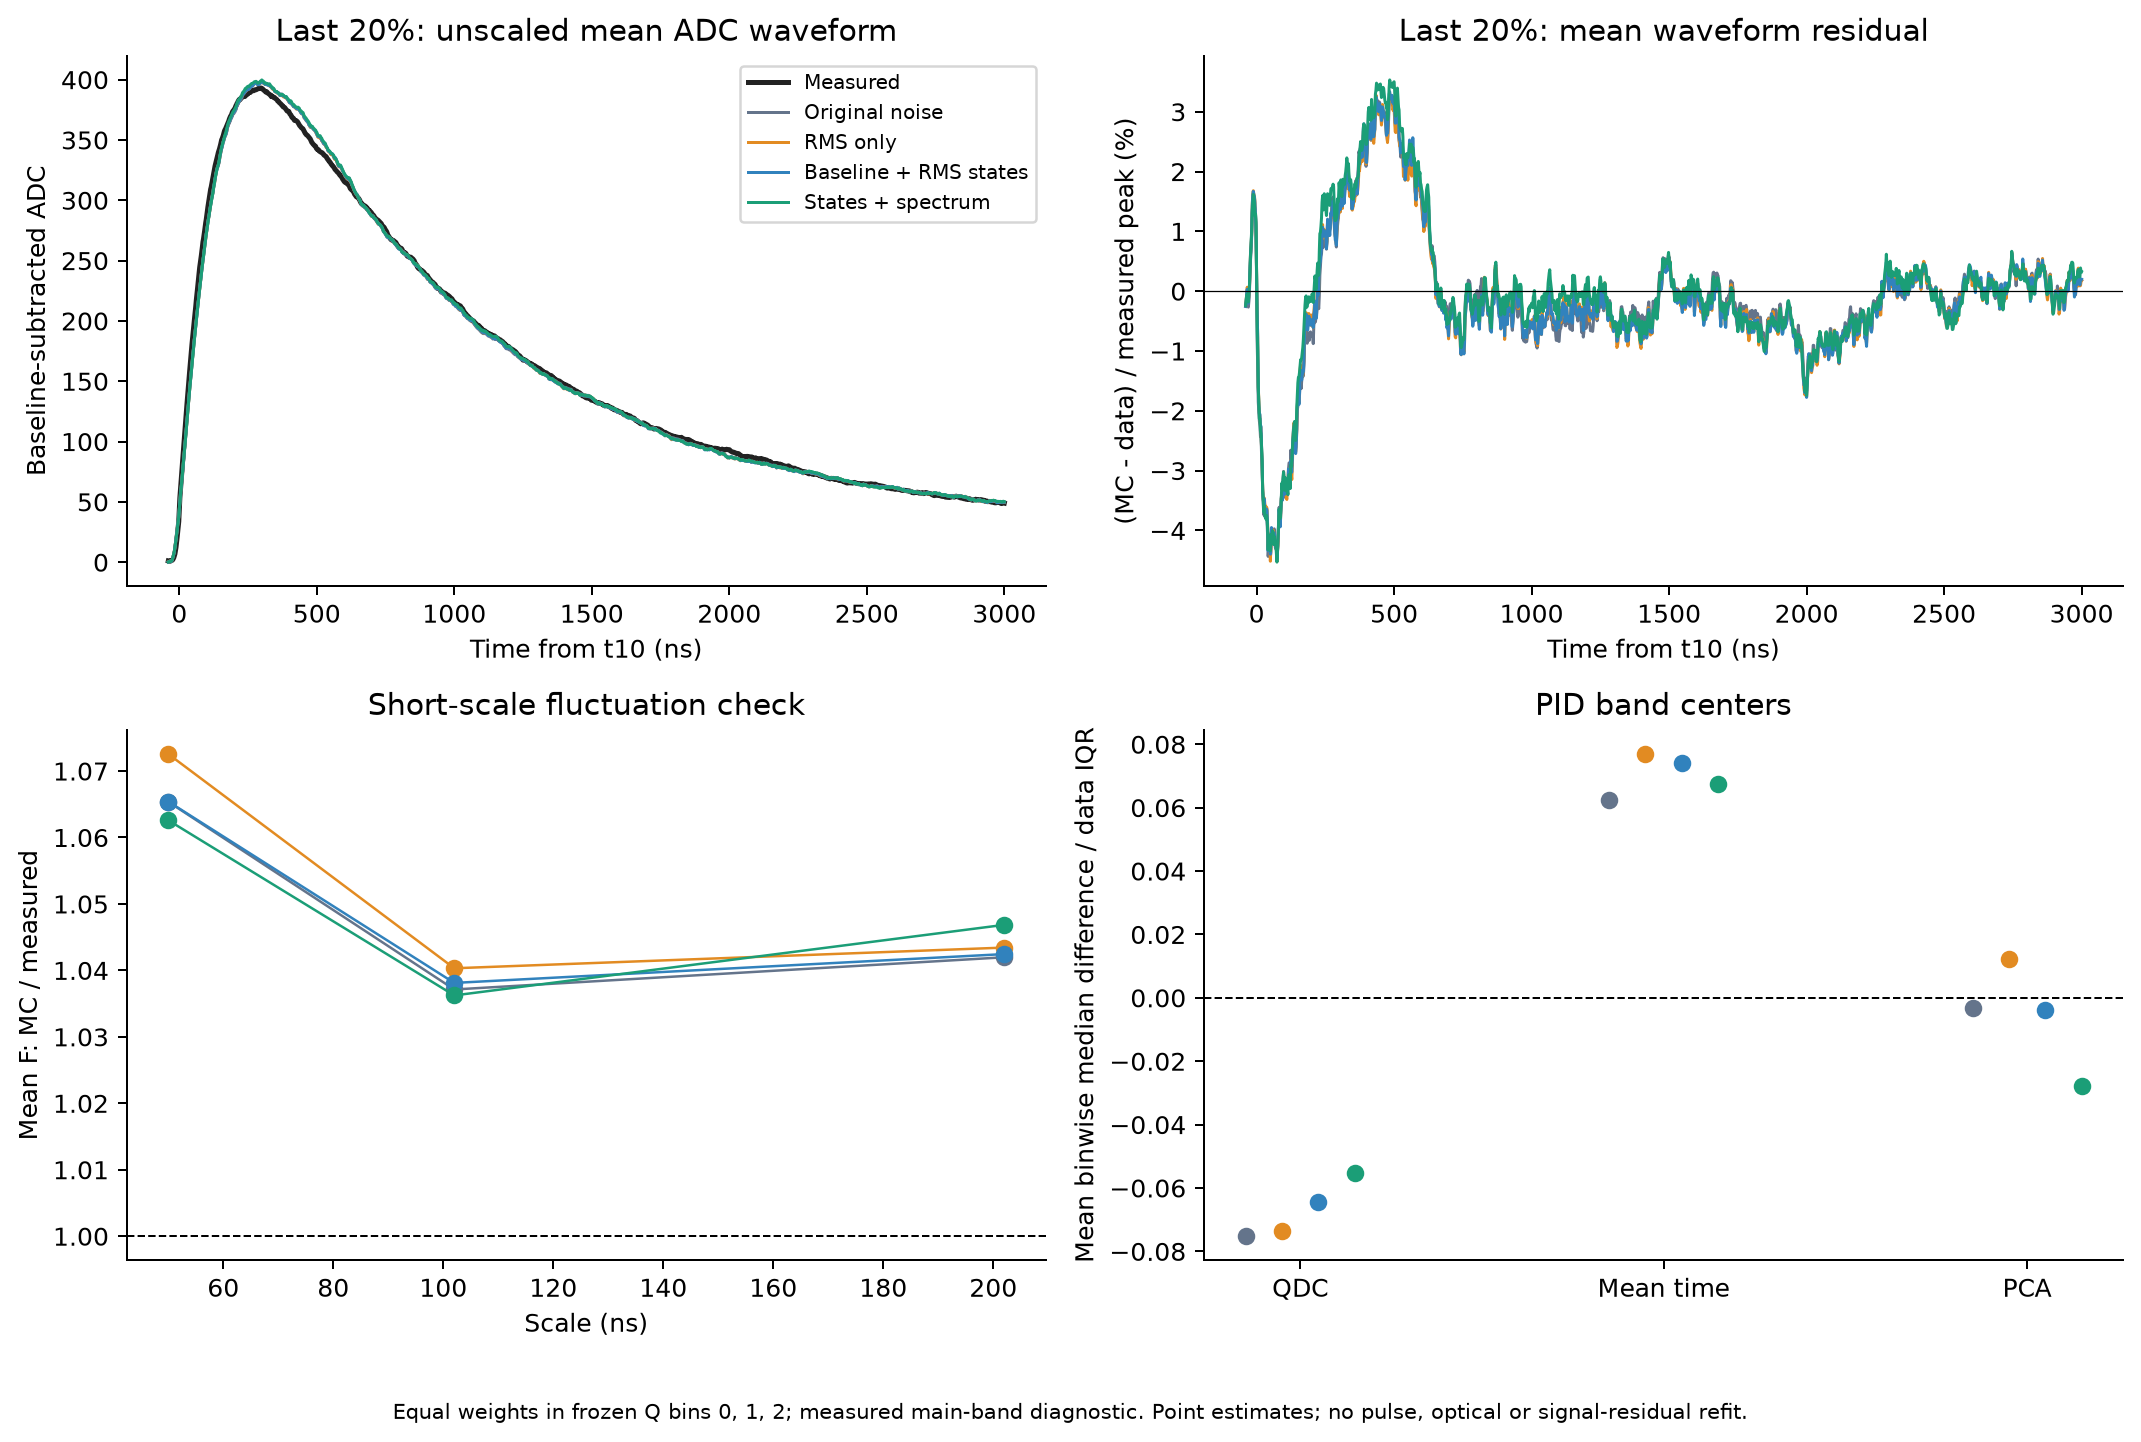

In [6]:
rows=[]
for seg in segments:
    for v in variants:
        a=r['checks'][seg]['variants'][v]['reselected']
        rows.append([seg,names[v],f"{100*a['mean_ADC_normalized_RMSE']:.3f}%",f"{a['mean_ADC_peak_ratio']:.4f}",numbers(a['F_ratio']),numbers(a['median_shift_in_data_IQR'])])
display(Markdown(table(['段','对照','均波形NRMSE/峰','均波形峰比','三个F比','三个中心差/实验IQR'],rows)))
display(Image(filename=str(OUT/'figures/noise_waveform_controls.png')))

## 6. 这一轮能得出什么，接下来怎么做

- 基线噪声状态漂移是应纳入的采集条件。后段QDC/PCA宽度点估计有所接近，但配对区间尚不能确认改善；固定事件后平均时间宽度比仍约0.81–0.83，完整解释尚缺证据。
- 本轮不选一个“最好看”的后段候选替换默认配置，也不声称已测得唯一的电子噪声机制。尤其要保留原谱/新谱两种状态对照及其残差。
- 下一项按既定顺序处理 **Co 平均时间中心与2–3 µs尾部**：在前60%训练中联合两源，加入平均时间/分段尾积分约束，检查旧700 ns慢分量边界与拟合权重；同时保护平均ADC、F和带宽结果。
- run12剩余带宽需要区分信号期残差、慢相关项、物理事件差异和参数族的不确定性。不能继续只增大基线RMS，也不能用留出PID结果反复选参数后仍称独立验证。
- 最终参数冻结后再补新种子母衰变，改善统计精度。当前18次重放没有增加独立α/γ样本；本轮也没有为变更噪声状态补齐共同状态的Co对照，不能据此更新α接受率/γ泄漏率。

这轮是有价值的约束：把“带宽来自噪声吧”拆成了可检验的噪声来源。平均波形接近、基线RMS接近、PID分布全部接近是三个不同的要求。


In [7]:
decision=read(OUT/'decision.json')
display(Markdown(decision['conclusion_zh']))
print('结果目录：',OUT.relative_to(PROJECT))
print('108行带宽数值：validation_table.csv；完整区间、筛选与噪声结果：assessment.json')
print('复现顺序：prepare_run12_noise_state.py → run_run12_noise_state.py → analyze_run12_noise_state.py → plot_run12_noise_state.py')
print('归档核查：simulation/verify_run12_noise_state.py；已完成目录拒绝覆盖，重算请另用新目录。')

结果目录： simulation/results/run12_noise_state_20261029
108行带宽数值：validation_table.csv；完整区间、筛选与噪声结果：assessment.json
复现顺序：prepare_run12_noise_state.py → run_run12_noise_state.py → analyze_run12_noise_state.py → plot_run12_noise_state.py
归档核查：simulation/verify_run12_noise_state.py；已完成目录拒绝覆盖，重算请另用新目录。


后段基线RMS中位数：实验 5.677 ADC，原模型 3.174，三个新对照 5.516–5.588。QDC带宽比由 0.897 变为 0.928–0.953，PCA由 0.858 变为 0.902–0.945；平均时间由 0.822 变为 0.817–0.846。三个新对照的三种带宽配对变化95%区间均包含0；现有统计量尚不能确认改善。噪声漂移应作为采集条件记录，但未完成三种PID带宽的一致性验证。